## Student Name : Mujtaba Hejji Alnuwaysir
## ID : 2240007941
## Class : 7MA2

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize

In [2]:
# Load cameraman image (already grayscale)
image = data.camera()
image = resize(image, (256, 256))  # Resize for faster FFT (optional)

# Get image size
M, N = image.shape

In [3]:
# Generate frequency grid (centered)
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)

In [4]:
# Compute Laplacian filter in frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

In [5]:
# Apply 2D FFT
F = np.fft.fft2(image)

In [6]:
# Apply Laplacian filter in frequency domain
F_lap = F * laplacian_filter

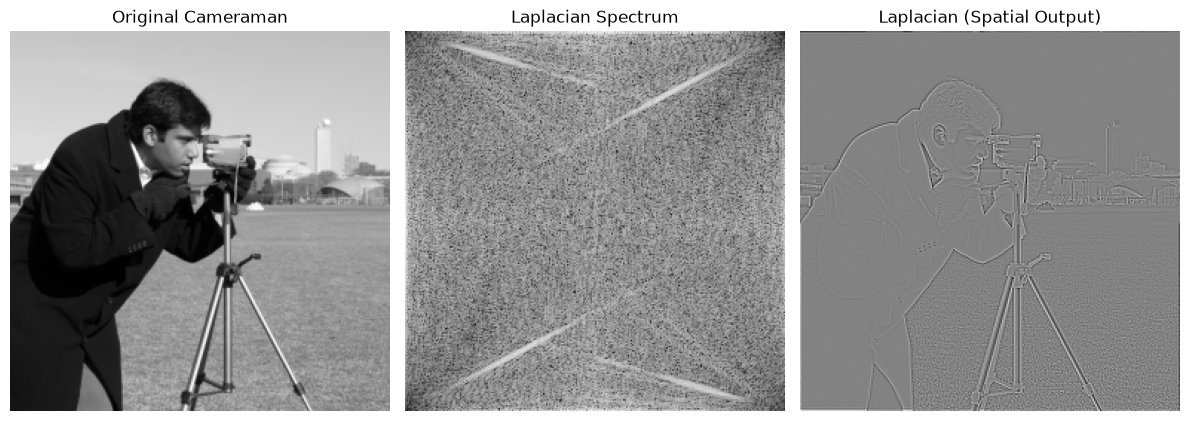

In [7]:
# Inverse FFT to get spatial result
laplacian_image = np.fft.ifft2(F_lap).real

# Plot results
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(F_lap)), cmap='gray')
plt.title('Laplacian Spectrum')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(laplacian_image, cmap='gray')
plt.title('Laplacian (Spatial Output)')
plt.axis('off')

plt.tight_layout()
plt.show()

In [8]:
# Load and resize image
from numpy.fft import fft2, ifft2, ifftshift

image = data.camera()
image = resize(image, (256, 256), anti_aliasing=True)
M, N = image.shape
print("Image size:", image.shape)

Image size: (256, 256)


In [9]:
# Sobel filters
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])
# Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    # Find center coordinates
    cy, cx = ph // 2, pw // 2
    # Insert kernel centered at the image center
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded)) 


In [10]:
# Shift before FFT to place (0,0) at top-left
H_x = center_embed_kernel(sobel_x, image.shape)
H_y = center_embed_kernel(sobel_y, image.shape)

In [11]:
# Compute FFT of image
F = fft2(image)
G_x = F * H_x
G_y = F * H_y
sobel_x_image = ifft2(G_x).real
sobel_y_image = ifft2(G_y).real
sobel_magnitude = np.sqrt(sobel_x_image**2 + sobel_y_image**2)

def normalize_for_display(arr):
    arr = np.abs(arr)
    return arr / arr.max() if arr.max() > 0 else arr

sobel_x_display = normalize_for_display(sobel_x_image)
sobel_y_display = normalize_for_display(sobel_y_image)
sobel_magnitude_display = normalize_for_display(sobel_magnitude)

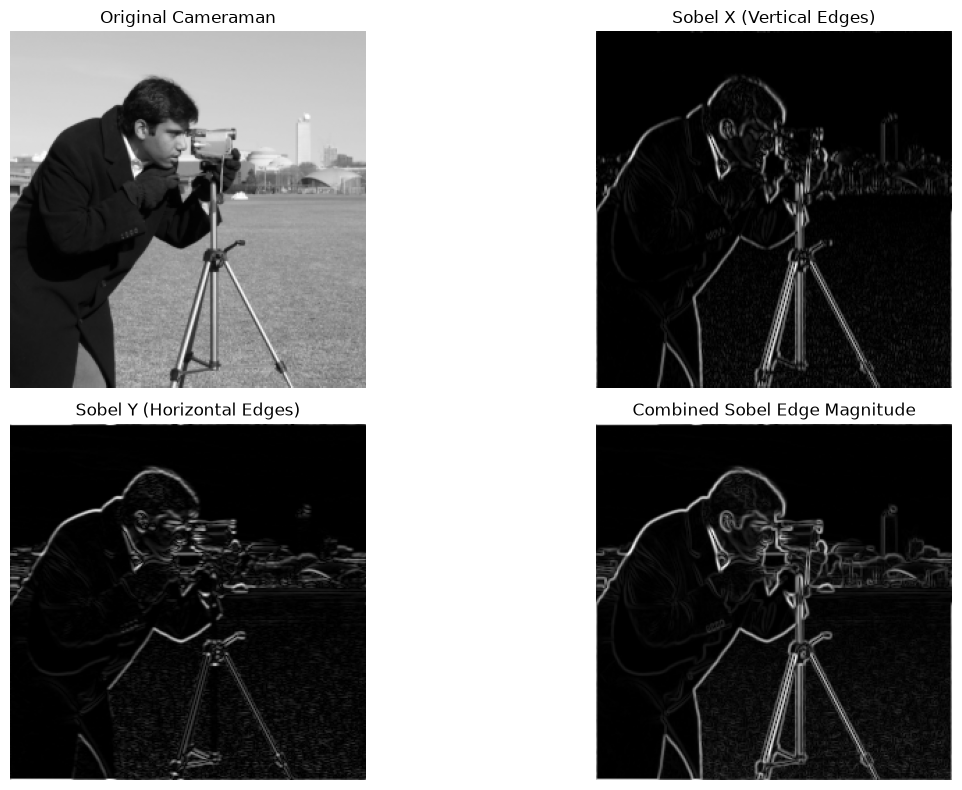

In [12]:
plt.figure(figsize=(14, 8))
plt.subplot(2, 2, 1); plt.imshow(image, cmap="gray"); plt.title("Original Cameraman"); plt.axis("off")
plt.subplot(2, 2, 2); plt.imshow(sobel_x_display, cmap="gray"); plt.title("Sobel X (Vertical Edges)"); plt.axis("off")
plt.subplot(2, 2, 3); plt.imshow(sobel_y_display, cmap="gray"); plt.title("Sobel Y (Horizontal Edges)"); plt.axis("off")
plt.subplot(2, 2, 4); plt.imshow(sobel_magnitude_display, cmap="gray"); plt.title("Combined Sobel Edge Magnitude"); plt.axis("off")
plt.tight_layout()
plt.show()